# 05 — SHAP Explanations for Alerts & Importance Drift

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Goal**: Per-alert SHAP explanations, global importance tracking, correlation with drift

In [1]:
# Setup
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import joblib

from data_prep import load_ieee_cis, prepare_features_target
from models import evaluate_model
from drift_detection import DriftMonitor
from shap_explainer import SHAPExplainer, compute_shap_stability

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = Path('../data')
MODELS_DIR = Path('../models')
REPORTS_DIR = Path('../reports')

print(f"Data root: {DATA_ROOT.absolute()}")

Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/notebooks/../data


## 1. Load Data, Model & Initialize SHAP

In [2]:
# Load data
ieee_df = load_ieee_cis(DATA_ROOT / 'ieee-cis')

def apply_fe(df, name):
    df = df.copy()
    if name == 'ieee-cis':
        df['hour'] = (df['TransactionDT'] // 3600) % 24
        df['day_of_week'] = (df['TransactionDT'] // 86400) % 7
        df['day'] = (df['TransactionDT'] // 86400).astype(int)  # matches 01_eda splits
        df['amount_log'] = np.log1p(df['TransactionAmt'])
        df['amount_round'] = (df['TransactionAmt'] == df['TransactionAmt'].round()).astype(int)
        if 'card1' in df.columns:
            df['card1_freq'] = df.groupby('card1')['card1'].transform('count')
    return df

ieee_df = apply_fe(ieee_df, 'ieee-cis')

def prepare_xy(df):
    drop_cols = ['TransactionID', 'TransactionDT', 'isFraud']
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df['isFraud'].astype('int8')
    # encode ALL non-numeric columns (parquet reloads M1-M9 etc. as object)
    for col in X.select_dtypes(exclude=['number']).columns:
        X[col] = X[col].astype('category').cat.codes
    return X.fillna(-999), y

X_all, y_all = prepare_xy(ieee_df)
feature_names = X_all.columns.tolist()
print(f"Features: {len(feature_names)}")

Features: 397


In [3]:
# Load model
model_path = MODELS_DIR / 'ieee_lightgbm.joblib'
if model_path.exists():
    model, _ = joblib.load(model_path), {}
    meta_path = model_path.with_suffix('.json')
    if meta_path.exists():
        import json
        with open(meta_path) as f:
            meta = json.load(f)
    print(f"Loaded: {meta.get('model', 'unknown')}")
else:
    from models import get_model
    from data_prep import handle_class_imbalance
    train_ieee = pd.read_parquet(DATA_ROOT / 'ieee-cis' / 'splits' / 'train.parquet')
    train_ieee = apply_fe(train_ieee, 'ieee-cis')
    X_train, y_train = prepare_xy(train_ieee)
    params = handle_class_imbalance(X_train, y_train)
    model = get_model('lightgbm', params)
    model.fit(X_train, y_train)
    print("Trained LightGBM on the fly")

# Get scores — align columns to the model's training features first
X_score = X_all.reindex(columns=model.feature_name_, fill_value=-999)
ieee_df['risk_score'] = model.predict_proba(X_score)[:, 1]
ieee_df['day'] = (ieee_df['TransactionDT'] // 86400).astype(int)

Loaded: lightgbm


In [4]:
# Initialize SHAP Explainer
# Use training data as background
train_ieee = pd.read_parquet(DATA_ROOT / 'ieee-cis' / 'splits' / 'train.parquet')
train_ieee = apply_fe(train_ieee, 'ieee-cis')
X_train_bg, _ = prepare_xy(train_ieee)

explainer = SHAPExplainer(model, X_train_bg, feature_names=feature_names, max_background=500)
print("SHAP Explainer initialized")

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


SHAP Explainer initialized


## 2. Per-Alert SHAP Explanations

In [5]:
# Get high-risk transactions (top 1% by score) from test period
test_data = ieee_df[ieee_df['day'] >= 60].copy()
X_test, y_test = prepare_xy(test_data)
X_test = X_test.reindex(columns=feature_names, fill_value=-999)  # drop risk_score extra, align to training features

# Top risky transactions
top_risky = test_data.nlargest(10, 'risk_score')
X_top = X_test.loc[top_risky.index]

print("=== Top 10 Riskiest Transactions ===")
for idx, row in top_risky.iterrows():
    x_row = X_top.loc[idx]
    explanation = explainer.explain_instance(x_row.to_frame().T, max_display=10)
    
    print(f"\nTransaction {idx}: Score={row['risk_score']:.4f}, True Label={row['isFraud']}")
    print(f"  Prediction: {explanation['prediction']:.4f}")
    print(f"  Top contributors:")
    for feat, val in explanation['feature_contributions'][:5]:
        print(f"    {feat}: {val:+.4f}")

=== Top 10 Riskiest Transactions ===

Transaction 316364: Score=0.9997, True Label=1
  Prediction: 8.1369
  Top contributors:
    C1: +1.6586
    V258: +0.7602
    V70: +0.5674
    V187: +0.5313
    V45: +0.3434

Transaction 316374: Score=0.9997, True Label=1
  Prediction: 8.1233
  Top contributors:
    C1: +1.7209
    V258: +0.9049
    V187: +0.5354
    V45: +0.4830
    V70: +0.3652

Transaction 301668: Score=0.9997, True Label=1
  Prediction: 8.0903
  Top contributors:
    C1: +1.5145
    V258: +0.9083
    V187: +0.5380
    V70: +0.3584
    V45: +0.3500

Transaction 301674: Score=0.9997, True Label=1
  Prediction: 8.0841
  Top contributors:
    C1: +1.7034
    V258: +0.9107
    V187: +0.5469
    V70: +0.3587
    ProductCD: +0.3462

Transaction 236769: Score=0.9997, True Label=1
  Prediction: 8.0316
  Top contributors:
    C1: +1.0704
    V258: +0.9980
    C14: +0.6099
    V187: +0.4730
    V70: +0.3516

Transaction 236772: Score=0.9997, True Label=1
  Prediction: 8.0316
  Top contrib

Generating waterfall for transaction 316364 (score=0.9997)


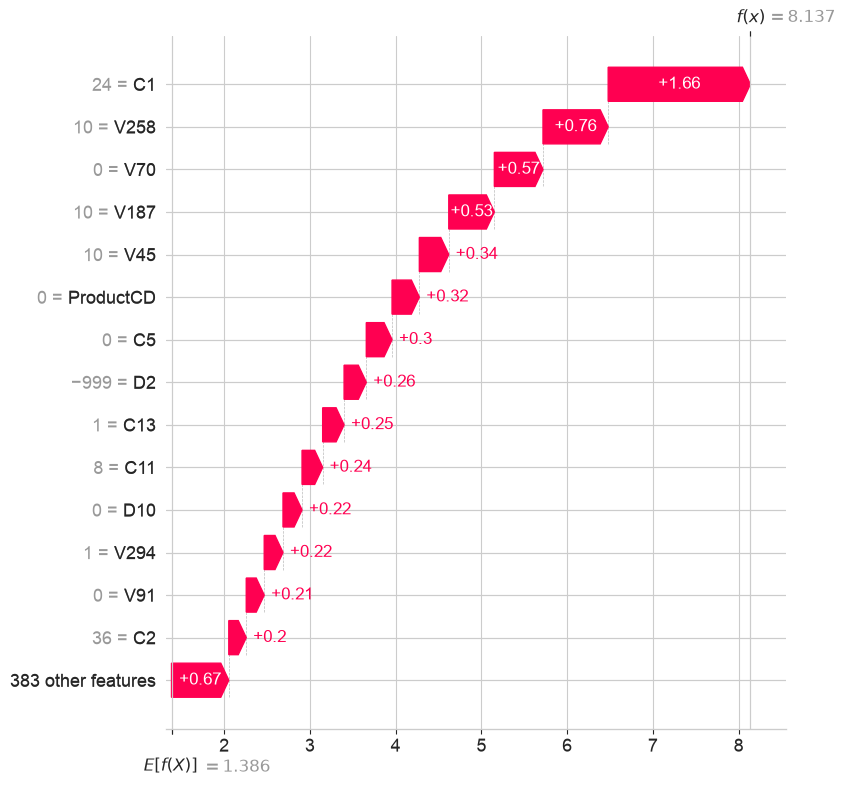

.values =
array([-1.26521595e-01,  3.18181234e-01,  4.13211076e-02,  2.71984981e-02,
        3.08510202e-02, -2.58536921e-03, -1.23948238e-03,  7.23491251e-02,
       -2.20030579e-03,  3.83577873e-02,  4.61955895e-02, -4.26404725e-02,
        6.46494055e-02, -1.85748344e-02,  1.65864867e+00,  2.03586813e-01,
        0.00000000e+00,  1.97456602e-02,  3.00352141e-01,  1.03882018e-01,
        3.68297413e-03,  9.99290117e-02,  6.03561674e-02,  8.51773111e-03,
        2.40397840e-01,  9.54191002e-03,  2.49863330e-01,  1.32479290e-03,
        6.25743354e-02,  2.58931703e-01, -1.91695962e-02,  9.83226487e-02,
        4.44596678e-02,  4.97594013e-03,  3.40981688e-03,  1.47912746e-02,
        4.47369937e-04,  2.22172382e-01,  1.23581070e-02,  3.91140128e-03,
        3.17884478e-03,  2.18183765e-02,  1.92010176e-01,  3.66318213e-04,
        9.70916502e-04,  1.37486532e-02,  3.04824610e-02, -1.10026294e-01,
        1.20521945e-02,  0.00000000e+00,  0.00000000e+00,  2.19664928e-03,
        0.00000

In [6]:
# Generate waterfall plot for first high-risk transaction
first_idx = top_risky.index[0]
x_first = X_top.loc[first_idx]
print(f"Generating waterfall for transaction {first_idx} (score={top_risky.loc[first_idx, 'risk_score']:.4f})")
explainer.plot_waterfall(x_first.to_frame().T, max_display=15, show=True)

## 3. Global Feature Importance (Mean |SHAP|)

=== Top 20 Global Features (Mean |SHAP|) ===


,feature,mean_abs_shap,std_shap,mean_shap
0,V70,0.359040,0.393331,-0.018805
1,card1_freq,0.307661,0.515465,-0.111346
2,hour,0.236532,0.115410,-0.235954
3,TransactionAmt,0.208311,0.261312,0.004155
4,C13,0.179240,0.280321,-0.001031
5,C2,0.152752,0.202819,0.023179
6,card1,0.143291,0.196468,-0.029509
7,D2,0.137763,0.188716,0.022644
8,C11,0.124823,0.167060,0.036313
9,V91,0.121644,0.140246,-0.008944


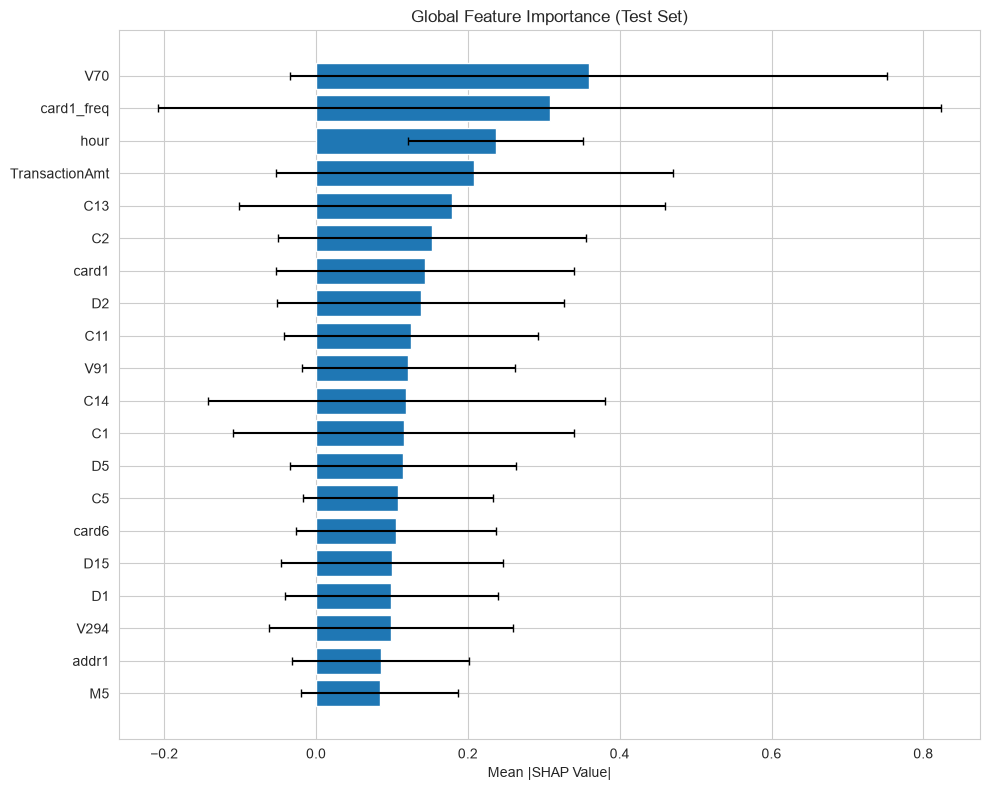

In [7]:
# Global importance on test set
importance_df = explainer.global_importance(X_test, max_samples=2000)
print("=== Top 20 Global Features (Mean |SHAP|) ===")
display(importance_df.head(20))  # type: ignore[unknown-name]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
top20 = importance_df.head(20).iloc[::-1]
ax.barh(range(len(top20)), top20['mean_abs_shap'], xerr=top20['std_shap'], capsize=3)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20['feature'])
ax.set_xlabel('Mean |SHAP Value|')
ax.set_title('Global Feature Importance (Test Set)')
plt.tight_layout()
plt.show()

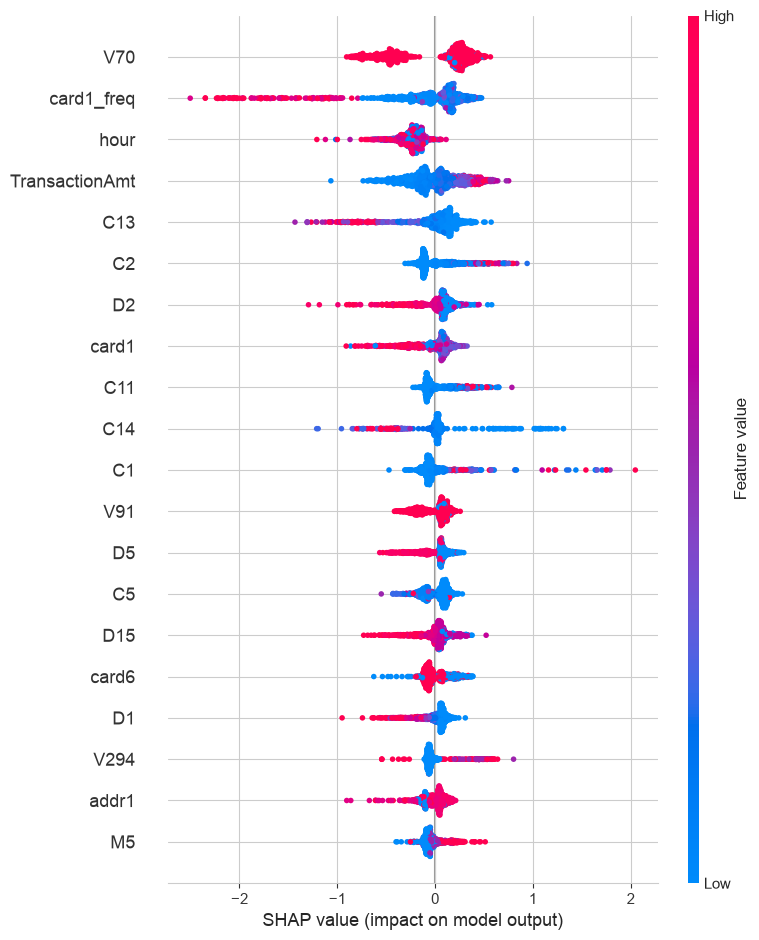

array([[ 3.05063492e-01, -1.95000240e-02,  1.48502976e-02, ...,
         2.13599534e-02, -8.00348075e-02,  1.57873004e-01],
       [-3.81734155e-01, -1.02267365e-02,  1.75214088e-01, ...,
        -3.03173235e-02, -1.24701765e-02, -2.07567017e+00],
       [ 1.94632826e-01,  1.12178929e-02,  3.03365318e-02, ...,
         1.58375847e-02, -1.60368684e-02,  3.33842698e-01],
       ...,
       [-1.37502097e-01,  8.84963521e-04,  1.41366418e-01, ...,
        -5.53302100e-02, -7.75487164e-03, -5.01221641e-01],
       [-4.20545323e-01,  7.27063130e-04, -1.11071712e-01, ...,
        -6.64603896e-02, -1.33072770e-02, -4.79004806e-01],
       [ 3.55060247e-01, -2.48560144e-02,  2.77451467e-02, ...,
         7.39306555e-02,  5.28661656e-02, -6.62628313e-02]],
      shape=(1000, 397))

In [8]:
# SHAP summary plot (beeswarm)
explainer.plot_summary(X_test.sample(n=min(2000, len(X_test)), random_state=42), plot_type='dot')

## 4. Importance Tracking Over Time Windows

In [9]:
# Track importance drift across 7-day windows
max_day = ieee_df['day'].max()
window_size = 7
step_size = 7  # Non-overlapping windows

importance_records = []
for window_start in range(30, max_day - window_size + 1, step_size):
    window_end = window_start + window_size
    window_data = ieee_df[(ieee_df['day'] >= window_start) & (ieee_df['day'] < window_end)]
    
    if len(window_data) < 100:
        continue
    
    X_win, y_win = prepare_xy(window_data)
    X_win = X_win.reindex(columns=feature_names, fill_value=-999)  # align to training features
    
    # Global importance for this window
    imp_df = explainer.global_importance(X_win, max_samples=min(1000, len(X_win)))
    
    # Track drift
    drift_result = explainer.track_importance_drift(imp_df, timestamp=f"day_{window_start}_{window_end}")
    
    importance_records.append({
        'window_start': window_start,
        'window_end': window_end,
        'importance_df': imp_df,
        'drift': drift_result.get('drift_from_previous'),
    })
    
    if drift_result.get('drift_from_previous'):
        drift = drift_result['drift_from_previous']
        print(f"Window {window_start}-{window_end}: Spearman={drift['spearman_correlation']:.3f}, Top-20 Overlap={drift['top_k_overlap']:.2f}")

Window 37-44: Spearman=0.981, Top-20 Overlap=1.00
Window 44-51: Spearman=0.975, Top-20 Overlap=1.00
Window 51-58: Spearman=0.987, Top-20 Overlap=1.00
Window 58-65: Spearman=0.980, Top-20 Overlap=1.00
Window 65-72: Spearman=0.982, Top-20 Overlap=1.00
Window 72-79: Spearman=0.984, Top-20 Overlap=1.00
Window 79-86: Spearman=0.977, Top-20 Overlap=1.00
Window 86-93: Spearman=0.971, Top-20 Overlap=1.00
Window 93-100: Spearman=0.979, Top-20 Overlap=1.00
Window 100-107: Spearman=0.983, Top-20 Overlap=1.00
Window 107-114: Spearman=0.986, Top-20 Overlap=1.00
Window 114-121: Spearman=0.982, Top-20 Overlap=1.00
Window 121-128: Spearman=0.987, Top-20 Overlap=1.00
Window 128-135: Spearman=0.985, Top-20 Overlap=1.00
Window 135-142: Spearman=0.979, Top-20 Overlap=1.00
Window 142-149: Spearman=0.973, Top-20 Overlap=0.95
Window 149-156: Spearman=0.983, Top-20 Overlap=0.95
Window 156-163: Spearman=0.984, Top-20 Overlap=0.95
Window 163-170: Spearman=0.981, Top-20 Overlap=0.95
Window 170-177: Spearman=0.98

## 5. Importance Drift Visualization

Importance history shape: (8337, 3)


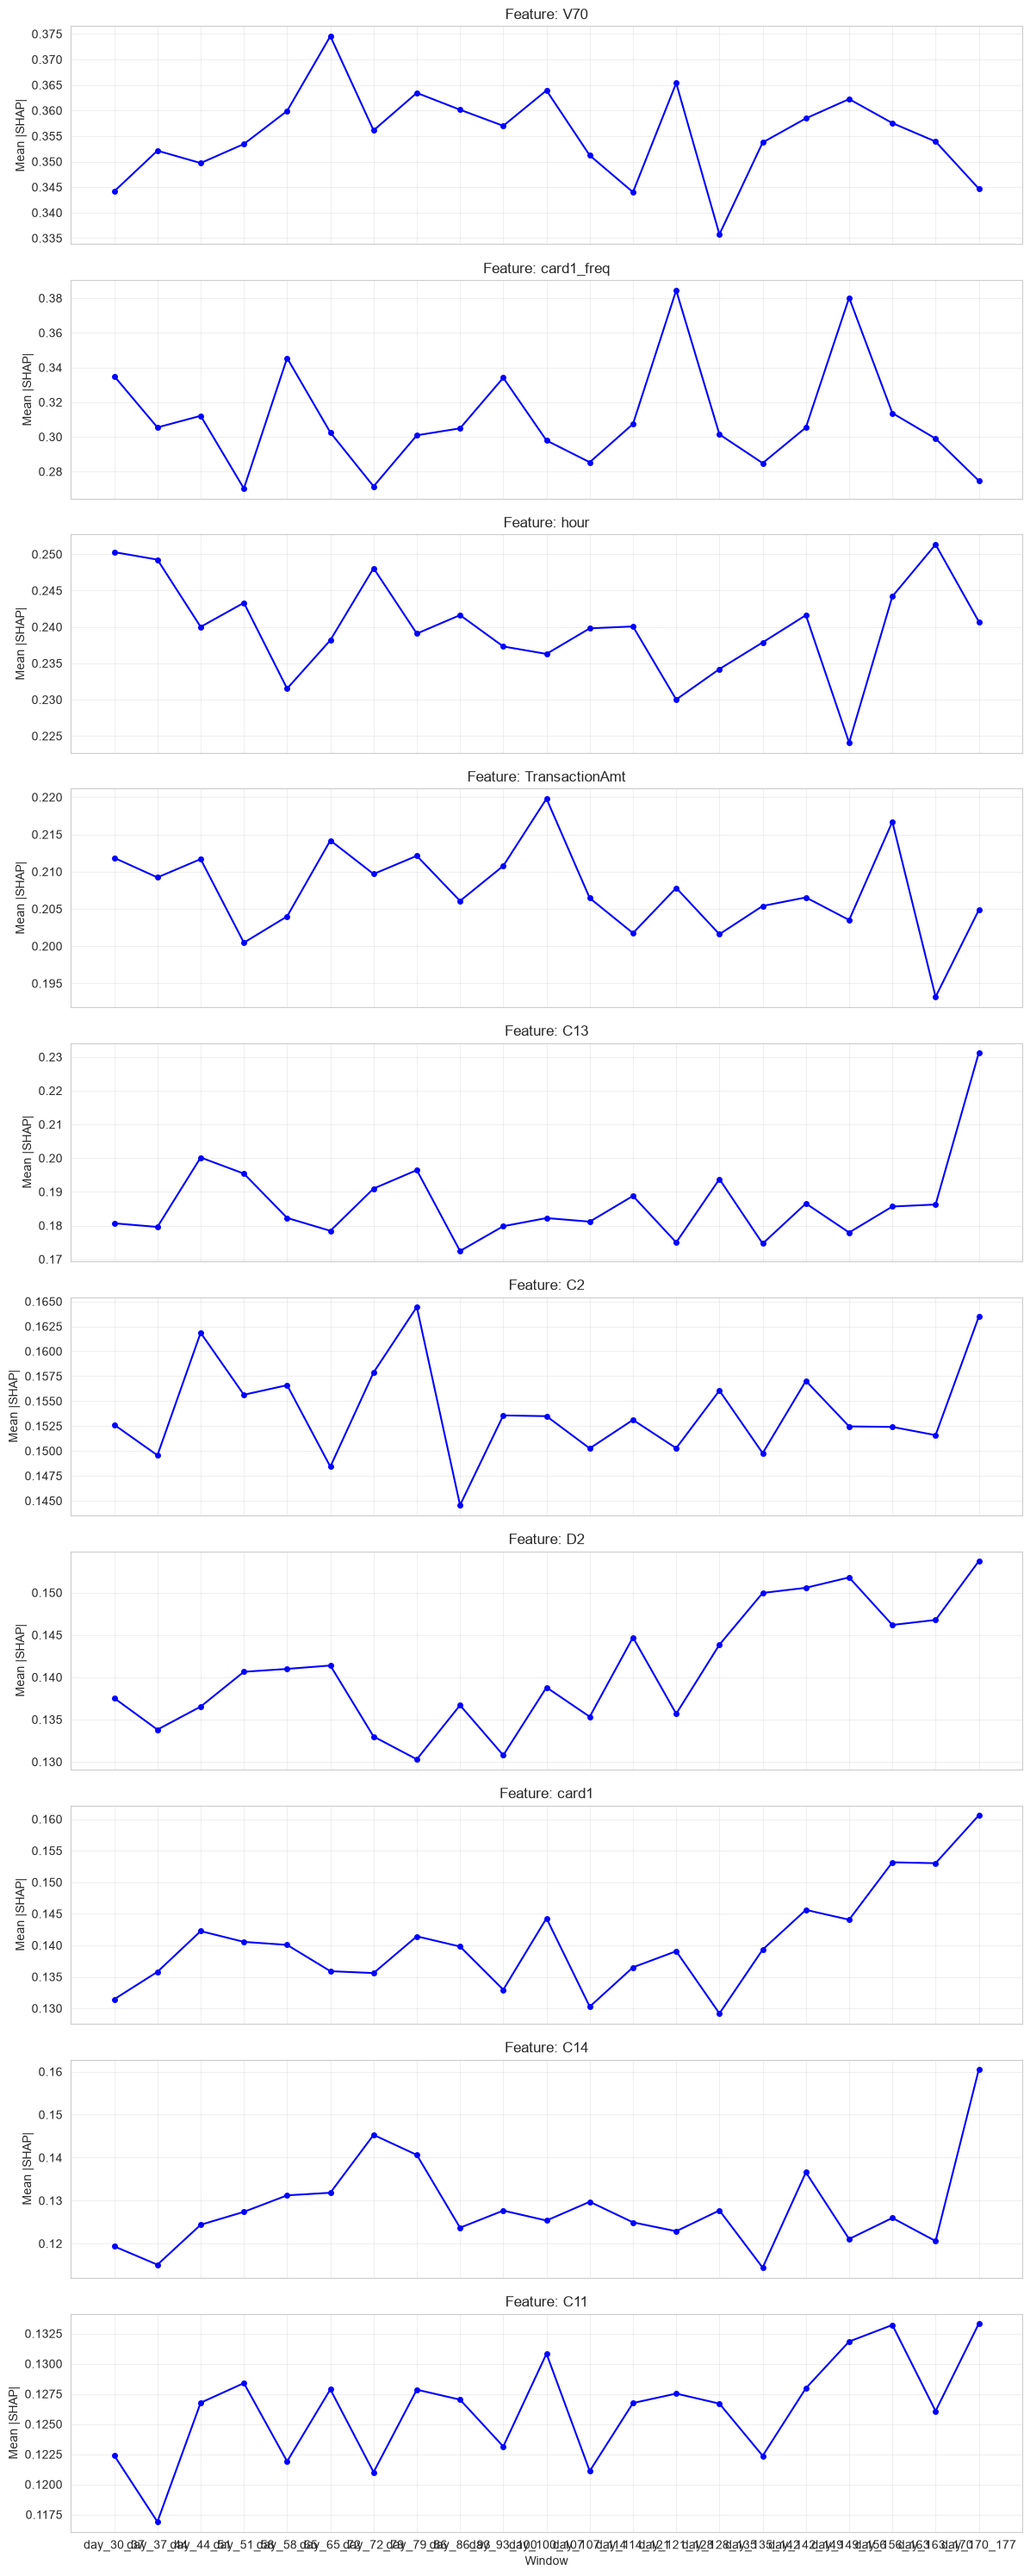

In [10]:
# Get importance history
history_df = explainer.get_importance_history()
print(f"Importance history shape: {history_df.shape}")

# Plot top features over time
if not history_df.empty:
    overall_top = history_df.groupby('feature')['importance'].mean().nlargest(10).index.tolist()
    
    fig, axes = plt.subplots(len(overall_top), 1, figsize=(12, 3*len(overall_top)), sharex=True)
    if len(overall_top) == 1:
        axes = [axes]
    
    for ax, feat in zip(axes, overall_top):
        feat_data = history_df[history_df['feature'] == feat]
        ax.plot(feat_data['timestamp'], feat_data['importance'], 'b-o', markersize=4)
        ax.set_ylabel('Mean |SHAP|')
        ax.set_title(f'Feature: {feat}')
        ax.grid(True, alpha=0.3)
    
    axes[-1].set_xlabel('Window')
    plt.tight_layout()
    plt.show()

## 6. SHAP Stability Analysis

In [11]:
# Compute stability metrics
stability_df = compute_shap_stability(history_df, top_k=20)
print("=== SHAP Stability (Top 20 Features) ===")
display(stability_df)  # type: ignore[unknown-name]

# Features with high CV (unstable importance)
unstable = stability_df[stability_df['cv'] > 0.5].sort_values('cv', ascending=False)
if not unstable.empty:
    print("\nUnstable features (CV > 0.5):")
    display(unstable)  # type: ignore[unknown-name]


=== SHAP Stability (Top 20 Features) ===


,feature,mean_importance,cv,trend,n_windows
0,V70,0.355313,0.024077,0.264023,21
13,C5,0.108114,0.025740,0.124383,21
2,hour,0.239948,0.027406,0.240297,21
3,TransactionAmt,0.207511,0.028270,0.100328,21
10,V91,0.120010,0.030118,0.115932,21
5,C2,0.154052,0.031609,0.160803,21
9,C11,0.126236,0.033082,-0.198631,21
18,M5,0.083319,0.033085,0.010281,21
19,addr1,0.082351,0.036196,0.321998,21
14,card6,0.107736,0.039921,-0.066432,21


## 7. Correlate SHAP Drift with PSI Alerts

In [12]:
# Load drift alerts from previous notebook
alerts_path = REPORTS_DIR / 'drift_alerts_log.csv'
if alerts_path.exists():
    alerts_df = pd.read_csv(alerts_path)
    print(f"Loaded {len(alerts_df)} drift alerts")
    
    # Get feature alerts
    feature_alerts = alerts_df[alerts_df['type'] == 'feature_drift']
    if not feature_alerts.empty:
        alerted_features = feature_alerts['column'].unique()
        print(f"Features with drift alerts: {list(alerted_features)}")
        
        # Check if these features also have SHAP importance drift
        for feat in alerted_features:
            if feat in history_df['feature'].values:
                feat_history = history_df[history_df['feature'] == feat].sort_values('timestamp')
                cv = feat_history['importance'].std() / feat_history['importance'].mean()
                print(f"  {feat}: SHAP CV={cv:.3f}, Mean importance={feat_history['importance'].mean():.4f}")
else:
    print("No drift alerts found. Run 04_drift_monitoring.ipynb first.")

Loaded 600 drift alerts
Features with drift alerts: ['C8', 'C10', 'C9', 'C4', 'dist2']
  C8: SHAP CV=0.165, Mean importance=0.0201
  C10: SHAP CV=0.217, Mean importance=0.0049
  C9: SHAP CV=0.082, Mean importance=0.0219
  C4: SHAP CV=0.372, Mean importance=0.0043
  dist2: SHAP CV=0.134, Mean importance=0.0122


## 8. Save Results

In [13]:
# Save importance history
history_df.to_csv(REPORTS_DIR / 'shap_importance_history.csv', index=False)
stability_df.to_csv(REPORTS_DIR / 'shap_stability.csv', index=False)
importance_df.to_csv(REPORTS_DIR / 'shap_global_importance.csv', index=False)
print(f"Results saved to {REPORTS_DIR}")

Results saved to ../reports


## 9. Summary & Next Steps

In [14]:
print("""
=== SHAP EXPLANATIONS COMPLETE ===

✅ Per-alert SHAP explanations (waterfall plots)
✅ Global feature importance (mean |SHAP|)
✅ SHAP summary plots (beeswarm)
✅ Importance tracking over time windows
✅ SHAP stability analysis (CV, trend)
✅ Correlation with PSI drift alerts
✅ Results saved to ../reports/

NEXT: Notebook 06_retraining_strategies.ipynb
- Compare Static vs Scheduled vs Drift-Triggered retraining
- Operational metrics: FP/100k, retrain frequency, model staleness
- Statistical significance testing
""")


=== SHAP EXPLANATIONS COMPLETE ===

✅ Per-alert SHAP explanations (waterfall plots)
✅ Global feature importance (mean |SHAP|)
✅ SHAP summary plots (beeswarm)
✅ Importance tracking over time windows
✅ SHAP stability analysis (CV, trend)
✅ Correlation with PSI drift alerts
✅ Results saved to ../reports/

NEXT: Notebook 06_retraining_strategies.ipynb
- Compare Static vs Scheduled vs Drift-Triggered retraining
- Operational metrics: FP/100k, retrain frequency, model staleness
- Statistical significance testing

